# Proches en métro, proches en revenus ?

## *La géographie du réseau de transports en communs en Île-de-France reflète-t-elle la géographie des inégalités de revenus dans la région ?*

## Introduction

*De la Plaine Monceau au quartier des Épinettes on parcourt tout l'espace social, la transition entre les extrêmes étant assurée par un glacis de classes moyennes. Ces contrastes sociaux importants voisinent pourtant à quelques rues près, même si la mixité sociale est menacée par un processus d'embourgeoisement qui fait tache d'huile et ne laisse guère de quartiers à l'écart.*

*Du sud-ouest au nord-est du 17e arrondissement, le parcours est à la fois historique et sociologique, des abords fortunés du parc Monceau aux confins bordés par les boulevards des Maréchaux et leurs HBM (Habitations à bon marché, ancêtres des HLM).*

Pinçon, M. et Pinçon-Charlot, M. (2014). I. Lire Paris. Sociologie de Paris (3e éd., p. 9-26). La Découverte. https://shs.cairn.info/sociologie-de-paris--9782707182623-page-9?lang=fr.

Parce qu'elles sont conçues pour relier des territoires différents, les lignes de transports en commun traversent logiquement des espaces socialement et économiquement hétérogènes. Ainsi, par exemple, l'usager quotidien de la ligne 4 ou du RER A n'occupe pas la même position dans l'échelle sociale selon qu'il se trouve au milieu ou à l'une des extrémités de ces lignes.

Si des territoires économiquement et socialement proches peuvent aussi l'être géographiquement, les transports en commun rapprochent des espaces parfois très différents, et constituent ainsi des axes le long desquels peuvent s'observer les contrastes.

Nous développons ici deux axes de réponse à cette question. Nous verrons dans un premier temps que les revenus tendent à décroître à mesure que l'excentricité par rapport au réseau augmente, y compris à distance géographique équivalente. Dans un second temps, nous verrons que le long de certaines lignes, des stations très proches affichent des revenus moyens très différents.

Si nous avons utilisé des agents LLM (en particulier Claude) pour nous aider à la production de certains codes de ce projet, notamment pour les parties visuelles, les solutions proposées par ces agents ont systématiquement été amendées et adaptées lorsque nous avons choisi de les garder.

## Données

Les deux principales sources de données utilisées pour ce projet sont les données IDFM et les données Filosofi.

In [1]:
!pip install -r requirements.txt

Ignoring pyproj: markers 'sys_platform == "darwin"' don't match your environment
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 115.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 76.0 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 76.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 90.0 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.5
    Uninstalling numpy-2.5.5:
      Successfully uninstalled numpy-2.5.5━━━━━━━━━━━━━━━━━━━━━━━━ 1/8 [numpy]
  Attempting uninstall: pandas0m━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/8 [networkx]
    Found existing installation: pandas 3.1.1━━━━━━━━━━━━━━━━━ 2/8 [networkx]
    Uninstalling pandas-3.1.1:0m╺━━━━━━━━━━━━━━━━━━━ 4/8 [pandas]
      Successfully uninstalled pandas-3.1.1━━━━━━━━━━━━━━━━━━━ 4/8 [pandas]
  Attempting uninstall: geopandas╺━━━━━━━━━━━━━━━━━━━ 4/8 [pandas]
    Found existing installation: geopandas 1.2.0━━━━━━━━━━━━━━

In [2]:
from pretraitement_donnees import telecharger_zip, URL_ZIP_FILOSOFI, URL_ZIP_IDFM
import numpy as np
import os
import pandas as pd
import geopandas as gpd                    
import matplotlib.pyplot as plt            
import statsmodels.formula.api as smf      

### Données FiLoSoFi (2021)

Les données FiLoSoFi sont des données territoriales calculées par l'Insee, sur des carreaux de 200mx200m, ici pour l'année 2021. Lorsque les carreaux contiennent moins de 11 ménages, les données sont imputées pour préserver le secret statistique.

In [3]:
%%time

from pretraitement_donnees import charger_filosofi, indicateurs_filosofi, definir_quantiles, construire_centres_carreaux
from visualisation_donnees import generer_carte_filosofi
import geopandas as gpd

telecharger_zip(URL_ZIP_FILOSOFI, "filosofi")  # Ne télécharge que si data/filosofi n'existe pas

df_filosofi = charger_filosofi("data/filosofi/france_metro/carreaux_200m_met.shp")
df_filosofi = indicateurs_filosofi(df_filosofi)  # nv = niveau de vie moyen par habitant

CPU times: user 16.1 s, sys: 6.54 s, total: 22.7 s
Wall time: 9min 27s


### Données IDFM (2026)

Île-de-France Mobilités (IDFM) propose de nombreuses données relatives aux lignes, trains, stations, horaires. Ces données vont nous servir à construire un graphe dont les sommets sont les stations et les arêtes les temps de trajet les plus courts entre deux stations.

In [4]:
from pretraitement_donnees import charger_arrets, charger_routes, charger_routes_etendu, charger_horaires, charger_parcours, charger_stations, charger_trips, construire_lignes_idfm, construire_stations, construire_positions_stations, construire_aretes, construire_graphe_reseau
telecharger_zip(URL_ZIP_IDFM, "idfm")  # Ne télécharge que si data/idfm n'existe pas
print(os.listdir("data/idfm"))

['trips.txt', 'ticketing_deep_links.txt', 'transfers.txt', 'routes.txt', 'object_codes_extension.txt', 'shapes.txt', 'calendar_dates.txt', 'attributions.txt', 'stops.txt', 'agency.txt', 'booking_rules.txt', 'pathways.txt', 'calendar.txt', 'stop_times.txt']


Les données IDFM ne contiennent pas moins de 14 fichiers .txt différents, au format CSV. Nous ne chargeons que ceux dont nous avons besoin pour construire les lignes et calculer les temps de trajet entre deux stations. 

In [5]:
print(len(pd.read_csv("data/idfm/routes.txt"))) 

2027


Il y a 2027 lignes différentes. Pour faciliter la visualisation et les traitements, nous décidons de ne garder seulement le réseau ferré (métro, RER, Transilien, tram)

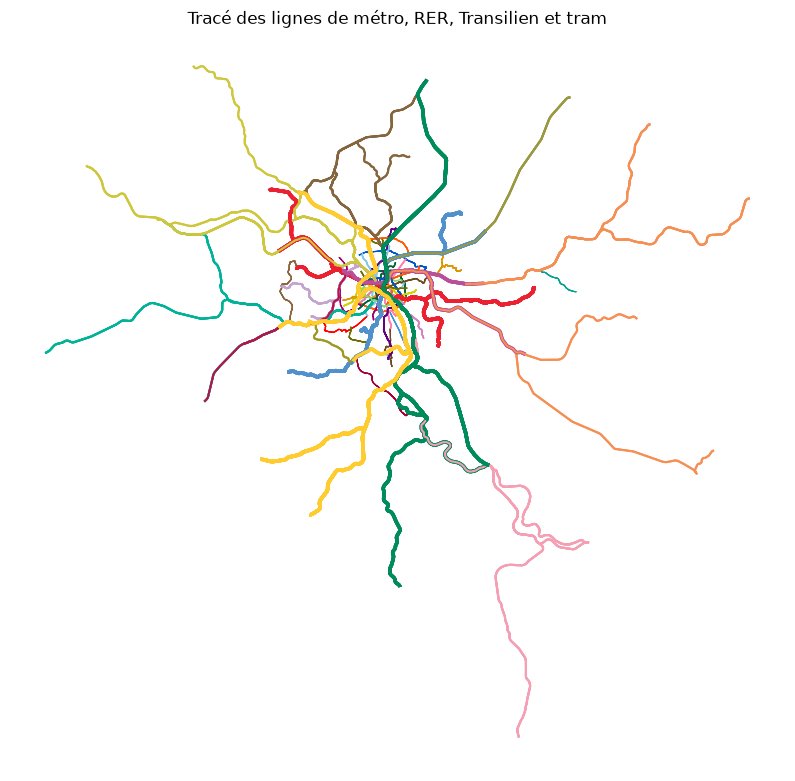

In [6]:
df_routes = charger_routes_etendu("data/idfm") # Lignes selon leur type : métro, RER, Transilien et tram
df_trips = charger_trips("data/idfm", df_routes) # Trains qui traversent chaque ligne
df_parcours = charger_parcours("data/idfm", df_trips) # Géométrie du parcours suivi par les trains de notre sélection

gpd_idfm = construire_lignes_idfm(df_parcours) # Passage en GeoPandas, avec changement de projection

EPAISSEUR = {"metro": 1, "tram": 0.8, "transilien": 1.5, "rer": 2.5} # Épaisseur du trait selon le type de ligne

ax = gpd_idfm.plot(
    color="#" + gpd_idfm["route_color"], # Couleurs officielles des lignes
    linewidth=gpd_idfm["mode"].map(EPAISSEUR).values, # RER plus épais, tram plus fin
    figsize=(10, 10),
)
ax.set_title("Tracé des lignes de métro, RER, Transilien et tram")
ax.set_axis_off()

Nous obtenons un GeoDataFrame qui contient le tracé géographique de chaque ligne du réseau ferré (métro, RER, Transilien et tram). Remarquons que certaines lignes possèdent de nombreux trains, auxquels correspondent de nombreux tracés.

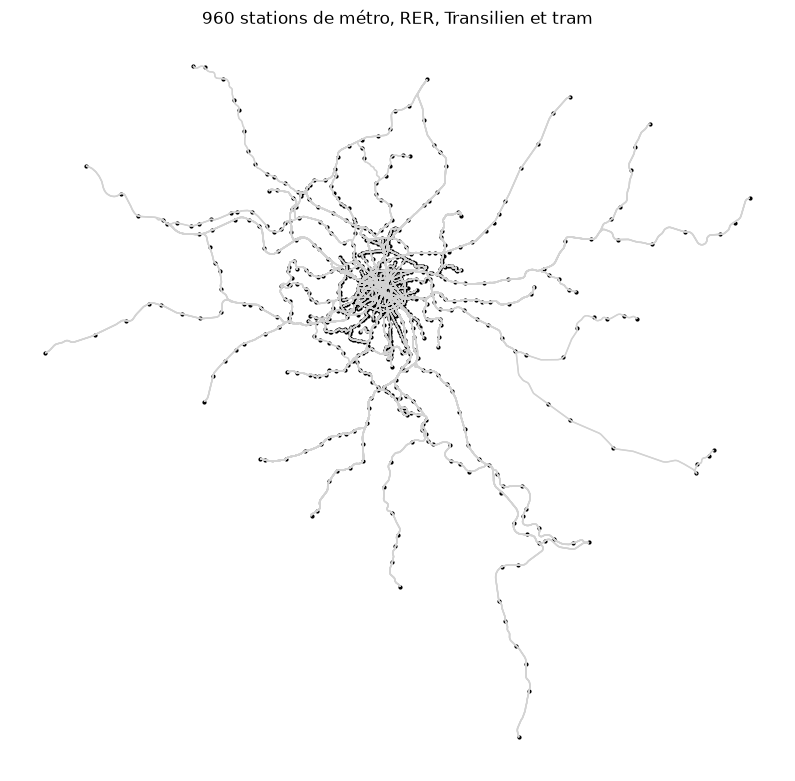

In [7]:
df_arrets = charger_arrets("data/idfm", df_trips) # Arrêts desservis par les trains
df_stations = charger_stations("data/idfm", df_arrets) # Stations desservies par les trains (plusieurs arrêts pour une même station)
gpd_stations = construire_stations(df_stations) # Position des stations (une ligne par station)

# Position des stations avec le nom de leur ligne (une ligne par couple station-ligne)
# -> utile pour l'ordre des stations et les cartes par ligne
gpd_stations_lignes = gpd.GeoDataFrame(
    df_stations,
    geometry=gpd.points_from_xy(df_stations["stop_lon"], df_stations["stop_lat"]),
    crs="EPSG:4326",
).to_crs("EPSG:2154")

ax = gpd_idfm.plot(color="lightgrey", linewidth=1, figsize=(10, 10)) # Lignes en fond
gpd_stations.plot(ax=ax, color="black", markersize=4)
ax.set_title(f"{len(gpd_stations)} stations de métro, RER, Transilien et tram")
ax.set_axis_off()

Nous obtenons 960 stations sur l'ensemble du réseau ferré (métro, RER, Transilien et tram).

In [8]:
df_horaires = charger_horaires("data/idfm", df_trips) # Horaires des trains à chaque arrêt
df_aretes = construire_aretes(df_horaires) # Calcul du temps minimal entre deux stations consécutives
graphe_reseau = construire_graphe_reseau(df_aretes) # Graphe orienté pondéré par le temps de transport entre les stations

print(df_aretes.describe())
print(graphe_reseau)

             temps
count  2516.000000
mean      3.162725
std       3.277788
min       0.733333
25%       1.516667
50%       2.325000
75%       3.608333
max      42.333333
DiGraph with 960 nodes and 2405 edges


Nous obtenons 2516 trajets entre deux stations consécutives, comptés dans chaque sens et pour chaque ligne : un tronçon desservi par plusieurs lignes apparaît donc plusieurs fois. Dans le graphe du réseau, où nous ne gardons que la ligne la plus rapide pour chaque tronçon, il reste 2405 liaisons.

### Données MOBPRO (2023)
Les données MOBPRO (recensement 2023, Insee) décrivent les trajets domicile-travail des actifs : commune de résidence, catégorie socioprofessionnelle (CSP) et mode de transport principal. Chaque ligne représente plusieurs personnes réelles, selon son poids `IPONDI`.

In [9]:
from pretraitement_donnees import URL_MOBPRO, telecharger_fichier, charger_mobpro, indicateurs_mobpro

telecharger_fichier(URL_MOBPRO, "RP2023_mobpro.parquet")  # Ne télécharge que si le fichier n'est pas dans data/

df_mob = charger_mobpro("data/RP2023_mobpro.parquet") # Actifs qui habitent en Île-de-France (région 11)
df_mob = indicateurs_mobpro(df_mob) # CSP et mode de transport en clair, lieu de résidence (arrondissement à Paris)

print(f"{len(df_mob):,} personnes interrogées".replace(",", " "))
print(f"{df_mob['IPONDI'].sum():,.0f} actifs franciliens représentés".replace(",", " "))

1 716 315 personnes interrogées
5 760 838 actifs franciliens représentés


L'échantillon compte environ 1,7 million de personnes interrogées, qui représentent, grâce aux poids `IPONDI`, environ 5,8 millions d'actifs franciliens.

### Contours des communes et des arrondissements
Pour relier les stations et les données MOBPRO, nous utilisons les contours des communes d'Île-de-France, Paris étant découpé en ses 20 arrondissements.

Ni MOBPRO, qui ne fournit qu'un code de commune, ni Filosofi, limité aux carreaux habités, ne contiennent la forme des communes. Nous utilisons donc des contours officiels, indispensables pour situer chaque station dans sa commune et représenter les données sur une carte.

In [10]:
from pretraitement_donnees import URL_COMMUNES, URL_ARRONDISSEMENTS, telecharger_fichier

# Communes d'Île-de-France (fichier public GitHub)
telecharger_fichier(URL_COMMUNES, "communes.geojson")
communes = gpd.read_file("data/communes.geojson")
communes = communes.rename(columns={"code": "INSEE_COM"})
communes = communes.to_crs("EPSG:2154")[["INSEE_COM", "nom", "geometry"]]

# Arrondissements de Paris (open data de la Ville de Paris)
telecharger_fichier(URL_ARRONDISSEMENTS, "arrondissements.geojson")
arr = gpd.read_file("data/arrondissements.geojson")
arr = arr.rename(columns={"c_arinsee": "INSEE_COM"})
arr["INSEE_COM"] = arr["INSEE_COM"].astype(int).astype(str)  # ex : "75113"
arr["nom"] = arr["INSEE_COM"].str[-2:].astype(int).map(lambda n: "1er" if n == 1 else f"{n}ème")
arr = arr.to_crs("EPSG:2154")[["INSEE_COM", "nom", "geometry"]]

# On remplace "Paris" (75056) par ses 20 arrondissements
communes = pd.concat([communes[communes["INSEE_COM"] != "75056"], arr], ignore_index=True)

print(f"{len(communes)} communes et arrondissements")

1295 communes et arrondissements


## I. Temps en transports, distance géographique, proximité économique

Dans cette partie, nous calculons pour chaque station le temps de transport par rapport à plusieurs pôles, et définissons comme temps de transport de référence le temps le moins élevé.

Comme indiqué plus haut, nous calculons un temps de trajet théorique pour rejoindre un pôle parmi un ensemble de pôles, en l'occurrence La Défense, Châtelet - Les Halles et Châtelet. 

Le temps de trajet d'une station vers le pôle le plus proche est calculé à partir d'un algorithme de Dijkstra appliqué au graphe construit précédemment, en négligeant les temps de correspondance.

On calcule ensuite la distance à vol d'oiseau entre chaque station et le pôle le plus proche.

### I.1 Le temps de trajet selon la distance

In [11]:
from analyse_donnees import preparer_stations_poles, preparer_carreaux
from visualisation_donnees import graphique_temps_distance, graphique_niveau_vie

# Temps de trajet et distance de chaque station jusqu'au pôle le plus proche
poles = ["Châtelet - Les Halles", "Châtelet", "La Défense"]
df_reg, df_temps, destinations = preparer_stations_poles(gpd_stations, graphe_reseau, poles)

L'observation du nuage de points temps de trajet / distance à un pôle à vol d'oiseau suggère une rupture vers 10km dans la relation entre distance à vol d'oiseau et temps de trajet. Nous construisons empiriquement un seuil qui sépare le mieux deux régressions linéaires. 

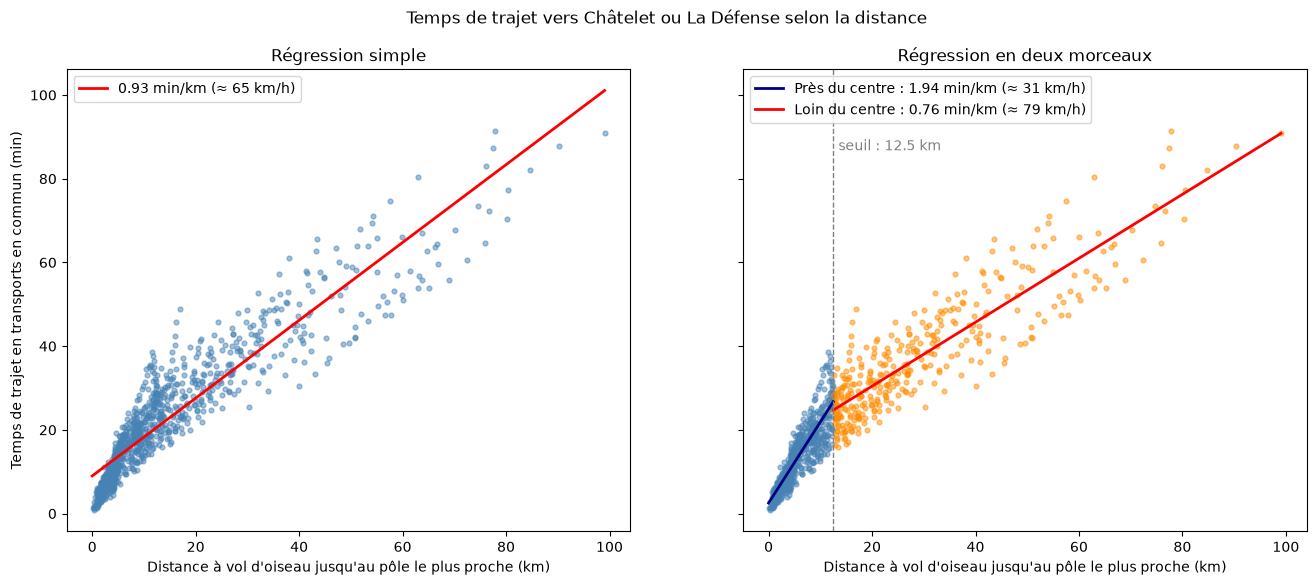

In [12]:
seuil = graphique_temps_distance(df_reg)

Après détermination de ce seuil, nous pouvons supposer que le seuil de 12,5 km correspond à la limite du métro : avant cette distance, le métro permet de se déplacer facilement grâce à un réseau dense, mais les trajets restent relativement lents (1,9 min par km) ; au-delà, le RER et le Transilien deviennent les principaux moyens de transport. Ils sont plus rapides (0,8 min par km) mais moins bien répartis. Les communes situées juste après cette limite sont donc les plus désavantagées : elles sont trop éloignées du métro et ne bénéficient pas toujours d'une bonne connexion au RER. Résultat : leurs habitants mettent souvent plus de temps à rejoindre Paris, même lorsque la distance reste raisonnable.

On effectue dans un deuxième temps une analyse plus fine, au niveau des carreaux de Filosofi. Nous effectuons d'abord une jointure entre Filosofi pour connaître la station la plus proche du centre de chaque carreau (dans la limite de 1500m), puis nous ajoutons un temps de marche (pour une vitesse de 75m/minutes) au temps de trajet de la station la plus proche. On effectue enfin une régression du niveau de vie sur le temps de trajet, et une régression du niveau de vie sur la distance à vol d'oiseau du pôle le plus proche (qui n'est pas nécessairement le même).

In [13]:
# Distance et temps de trajet vers le pôle le plus proche pour chaque carreau de 200 m
carreaux = preparer_carreaux(df_filosofi, gpd_stations, df_temps, destinations)

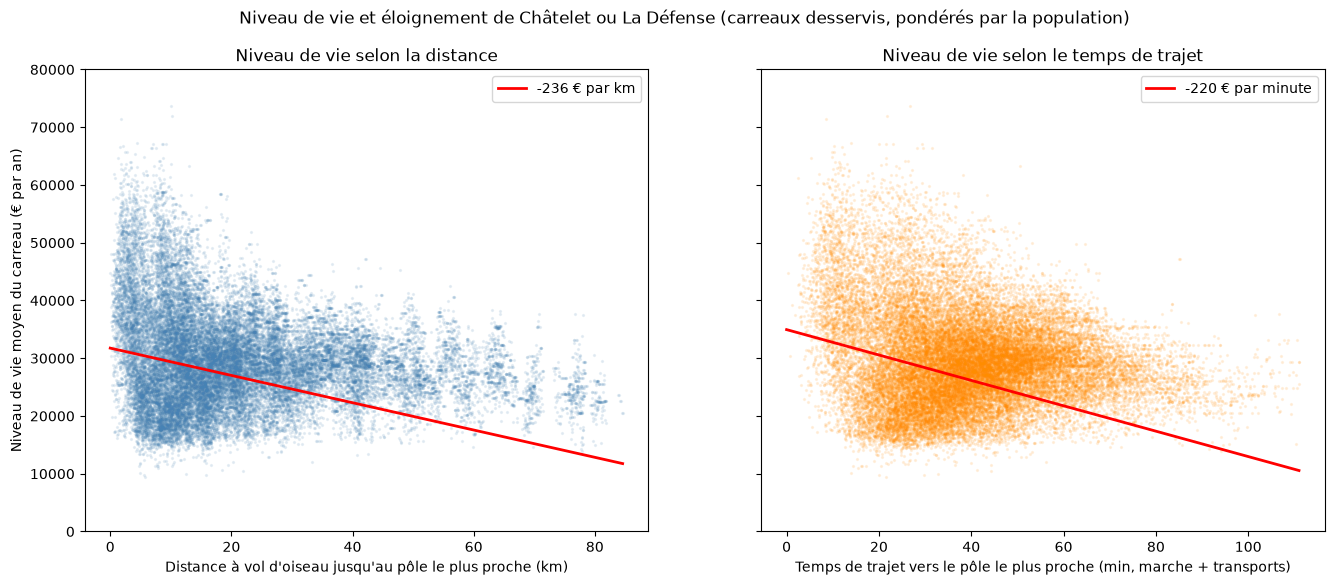

Niveau de vie ~ distance
                 Coef.  Std.Err.  P>|t|
Intercept    31755.902    71.209    0.0
distance_km   -236.393     4.237    0.0
R² = 0.083

Niveau de vie ~ temps
                 Coef.  Std.Err.  P>|t|
Intercept    34958.503   102.664    0.0
temps_total   -219.830     3.263    0.0
R² = 0.116



In [14]:
m_dist, m_temps = graphique_niveau_vie(carreaux)

Le niveau de vie diminue significativement avec l'éloignement du pôle le plus proche (Châtelet ou La Défense) : -236€ par an pour chaque kilomètre, et -220€ pour chaque minute de trajet supplémentaire. Le temps de trajet explique légèrement mieux les écarts de niveau de vie que la distance (R² de 11,6% contre 8,3%), ce qui suggère que l'accessibilité réelle compte davantage que l'éloignement géographique. Ces deux variables n'expliquent toutefois qu'une faible part des inégalités, qui dépendent surtout de la localisation des quartiers (ouest aisé, nord-est plus modeste).


### I.2 À distance à vol d'oiseau égale, la connexion fait-elle une différence ?

Puisque le temps de transport est étroitement lié à la distance aux pôles, il est raisonnable de se demander si, à distance à vol d'oiseau aux pôles égale, le temps de transport informe encore sur le niveau de vie.

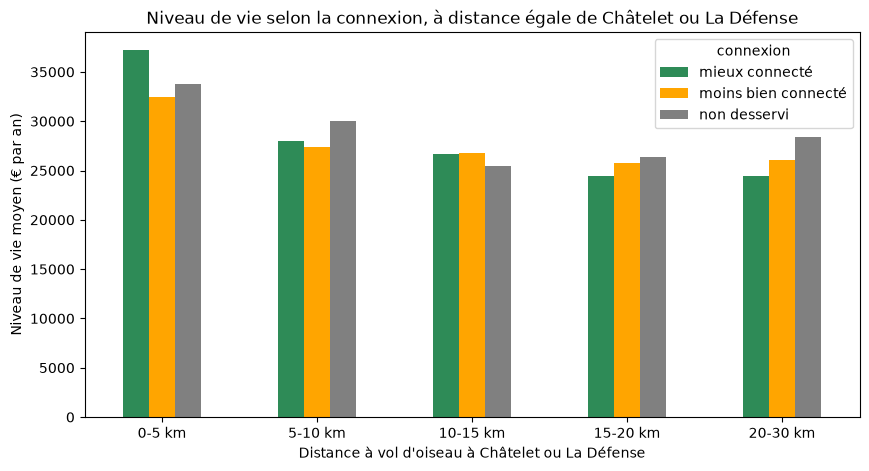

In [15]:
from analyse_donnees import comparer_nv_a_distance_egale
from visualisation_donnees import generer_graphique_connexion

# Dans chaque tranche de distance au pôle le plus proche, un carreau est "mieux connecté"
# si son temps de trajet est inférieur à la médiane de la tranche
df_comparaison = comparer_nv_a_distance_egale(
    carreaux.rename(columns={"distance_km": "distance_destination"}), bornes=[0, 5, 10, 15, 20, 30]
)
ax = generer_graphique_connexion(df_comparaison)
ax.set_title("Niveau de vie selon la connexion, à distance égale de Châtelet ou La Défense")
plt.show()

À distance à vol d'oiseau égale du pôle le plus proche, nous comparons les carreaux dont le temps de trajet est inférieur à la médiane de leur tranche, autrement dit les mieux connectés, aux autres. Près du centre, une meilleure connexion est associée à un niveau de vie plus élevé : à moins de 5 km, les carreaux mieux connectés ont un niveau de vie moyen de 37 200€ par an, contre 32 400€ pour les autres. L'écart se réduit entre 5 et 10 km (28 000€ contre 27 400€) puis disparaît entre 10 et 15 km.

Au-delà de 15 km, la relation s'inverse : les carreaux les mieux connectés sont légèrement moins aisés (24 500€ contre 25 700€ à 26 100€), et ce sont les carreaux non desservis par le réseau ferré qui ont le niveau de vie le plus élevé (26 400€ entre 15 et 20 km, 28 300€ entre 20 et 30 km). Loin des pôles, la desserte ferrée n'est donc plus associée à l'aisance, ce qui peut refléter des espaces périurbains aisés où l'on se déplace surtout en voiture. Les carreaux situés à plus de 30 km (environ 1,6 million d'habitants) ne sont pas pris en compte ici.

Comme dans la sous-partie précédente, nous assimilons ce seuil à la fin de la zone couverte par le métro.

### Conclusion de la partie I

Si distance à vol d'oiseau à des pôles, d'une part, et accessibilité des pôles en transport, d'autre part, sont étroitements liées, leur pouvoir informatif sur le niveau de vie s'inverse à la frontière du métro. Bénéficier de la proximité du métro ou du tram rapproche le niveau de vie des banlieues de celui, élevé, des pôles. À l'inverse, la connexion par RER ou transilien rappelle davantage la distance objective qui sépare la grande banlieue de la capitale. 

## II. Écarts entre des stations consécutives, hétérogénéité des lignes

La partie I a montré que le niveau de vie baisse avec le temps de trajet vers le pôle le plus proche (Châtelet ou La Défense), mais que ce temps n'explique qu'une petite part des écarts de revenus (R² de 11,6 %). Nous changeons donc de point de vue : au lieu de comparer chaque quartier au centre, nous comparons entre eux les quartiers **d'une même ligne**, qui ne sont qu'à quelques minutes les uns des autres. **Des habitants proches dans le réseau ont-ils des niveaux de vie proches ?**

Pour suivre les contrastes de revenus station par station, et pas seulement commune par commune, nous utilisons le niveau de vie de Filosofi, mesuré sur des carreaux de 200 m.

- **II.1 Le RER B** : la part d'ouvriers autour des gares, à partir des données MOBPRO ;
- **II.2 Les montagnes** : le niveau de vie le long du RER B et des lignes de métro 13 et 1 ;
- **II.3 L'hétérogénéité des lignes** : toutes les lignes de métro et de RER comparées, pour savoir si les écarts de revenus tiennent à la limite de Paris.

En annexe : le détail de la méthode, les autres lignes, la carte des communes plus riches que Paris et le relief du niveau de vie à Paris.

### II.1 Le RER B : la part d'ouvriers autour des gares

In [16]:
from visualisation_donnees import carte

# Toutes les données dont les cartes ont besoin, regroupées en un seul "paquet"
donnees_cartes = dict(
    df_mob=df_mob, communes=communes, arr=arr,
    gpd_idfm=gpd_idfm, gpd_stations_lignes=gpd_stations_lignes,
)

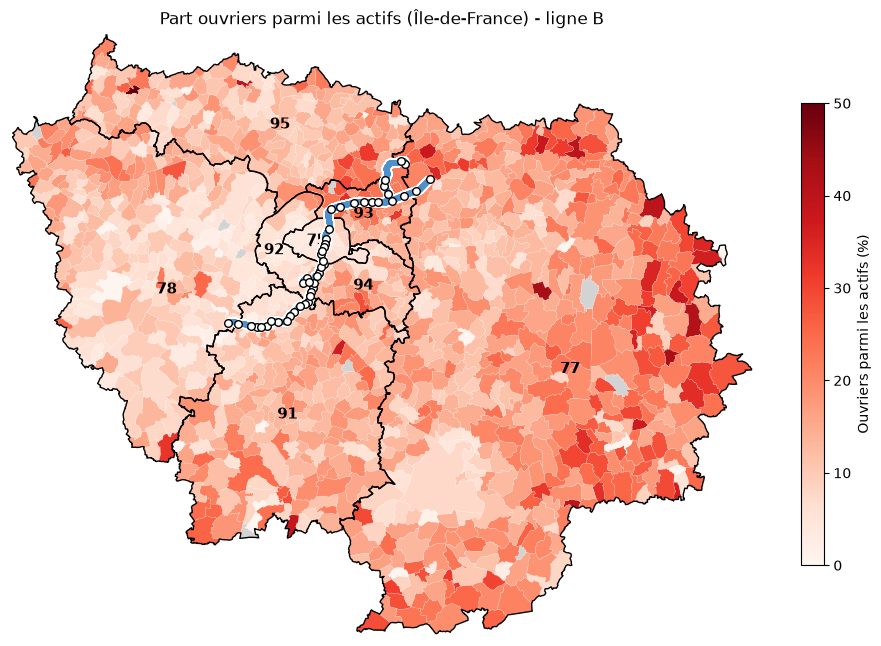

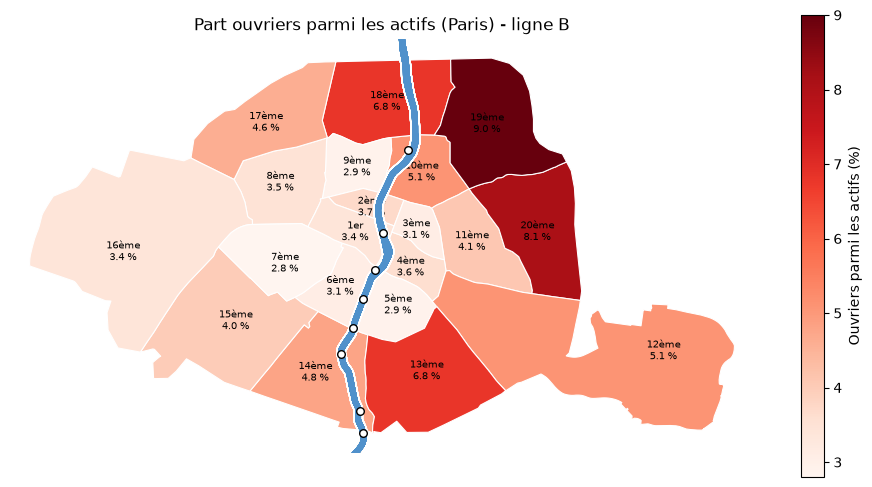

In [17]:
carte("Ouvriers", zone="idf", ligne="B", **donnees_cartes)    # RER B sur toute l'Île-de-France
carte("Ouvriers", zone="paris", ligne="B", **donnees_cartes)  # RER B dans Paris

In [18]:
from analyse_donnees import resume_ligne

# Découpage du RER B : Paris, banlieue nord, banlieue sud
zones_rer_b = {
    "Paris": ["75"],
    "Banlieue nord": ["93", "95", "77"],
    "Banlieue sud": ["92", "94", "91", "78"],
}

resume_ligne("B", "Ouvriers", zones=zones_rer_b, **donnees_cartes)

Ligne B : part ouvriers parmi les actifs

               Gares  Moyenne (%)  Min (%)  Max (%)
zone                                               
Banlieue nord     15         24.0     20.8     33.5
Banlieue sud      25          6.6      4.2     10.0
Paris              7          3.9      2.9      5.1

Part la plus forte :
                   stop_name          nom          zone  part
La Courneuve - Aubervilliers    Courneuve Banlieue nord  33.5
              Sevran - Livry       Sevran Banlieue nord  26.2
         Sevran - Beaudottes       Sevran Banlieue nord  26.2
             Le Blanc-Mesnil Blanc-Mesnil Banlieue nord  25.9
                      Drancy       Drancy Banlieue nord  23.7

Part la plus faible :
              stop_name    nom         zone  part
Saint-Michel Notre-Dame   5ème        Paris   2.9
             Port Royal   5ème        Paris   2.9
             Luxembourg   6ème        Paris   3.1
  Châtelet - Les Halles    1er        Paris   3.4
               Robinson Sceaux 

Le RER B relie des territoires socialement très différents. Dans Paris, il traverse des arrondissements où les ouvriers sont rares : 3,9 % des actifs en moyenne autour des sept gares parisiennes, avec un minimum de 2,9 % dans le 5e arrondissement (Saint-Michel Notre-Dame, Port-Royal). En dehors de Paris, la part d'ouvriers est nettement plus élevée : 13 % en moyenne autour des gares de banlieue, soit plus de trois fois plus qu'à Paris.

Mais la banlieue n'est pas homogène pour autant. Au nord, en Seine-Saint-Denis, les communes desservies comptent en moyenne 24 % d'ouvriers parmi leurs actifs, et jusqu'à 33,5 % à La Courneuve, soit plus de dix fois plus qu'à Saint-Michel, à moins de 15 minutes de trajet. Au sud, dans les Hauts-de-Seine et l'Essonne, cette part retombe à 6,6 % en moyenne, et à 4,2 % seulement à Sceaux (Robinson), presque au niveau de Paris. Une même ligne relie donc un nord populaire et un sud aisé, en passant par un centre parisien où les ouvriers sont presque absents.

In [19]:
import matplotlib.pyplot as plt

from analyse_donnees import (
    ajouter_communes_stations,
    calculer_carreaux_traverses,
    calculer_profils_zones,
    calculer_nv_par_commune,
    calculer_nv_par_station,
    calculer_temps_trajet,
    classer_carreaux_zones,
    construire_grille_nv,
    joindre_carreaux_stations,
    mesurer_heterogeneite_lignes,
    positionner_stations_ligne,
)
from pretraitement_donnees import (
    URL_ZIP_FILOSOFI,
    URL_ZIP_IDFM,
    charger_arrets,
    charger_communes,
    charger_filosofi,
    charger_horaires,
    charger_parcours,
    charger_routes,
    charger_stations,
    charger_trips,
    construire_aretes,
    construire_centres_carreaux,
    construire_graphe_reseau,
    construire_lignes_idfm,
    construire_stations,
    indicateurs_filosofi,
    telecharger_zip,
)
from visualisation_donnees import (
    ajouter_selecteur_lignes,
    enregistrer_graphique,
    generer_carte_communes_riches,
    generer_halteres_paris_banlieue,
    generer_montagnes_par_ligne,
    generer_relief_3d,
)

### Préparation des données pour II.2 et II.3

- **Niveau de vie** : carreaux de 200 m de Filosofi (Insee, 2021), avec pour chacun le nombre d'habitants et la somme de leurs niveaux de vie.
- **Réseau** : lignes de métro et de RER d'Île-de-France Mobilités, avec leurs tracés, leurs stations et les temps de parcours entre stations.
- **Rattachement** : chaque carreau est rattaché à sa station la plus proche, à moins de 1,5 km.
- **Moyennes** : par station, par commune (par arrondissement à Paris) et pour l'Île-de-France, toujours pondérées par la population.

In [20]:
# df_filosofi est déjà chargé dans la partie « Données »
gpd_centres = construire_centres_carreaux(df_filosofi)

In [21]:
# Métro et RER seulement (charger_routes ajoute sinon le tram et le Transilien)
df_routes = charger_routes("data/idfm", modes=("metro", "rer"))
df_trips = charger_trips("data/idfm", df_routes)
gpd_idfm = construire_lignes_idfm(charger_parcours("data/idfm", df_trips))

df_arrets = charger_arrets("data/idfm", df_trips)
df_stations = charger_stations("data/idfm", df_arrets)
gpd_stations = construire_stations(df_stations)

In [22]:
df_horaires = charger_horaires("data/idfm", df_trips)
graphe_reseau = construire_graphe_reseau(construire_aretes(df_horaires))
destinations = gpd_stations.loc[
    gpd_stations["stop_name"].isin(["Châtelet - Les Halles", "Châtelet", "La Défense"]),
    "stop_id",
]
df_temps = calculer_temps_trajet(graphe_reseau, destinations)

gpd_carreaux = joindre_carreaux_stations(
    gpd_centres, gpd_stations, df_temps, distance_max=1500, vitesse_marche=75
)

In [23]:
df_nv = calculer_nv_par_station(gpd_carreaux)
nv_moyen = gpd_carreaux["ind_snv"].sum() / gpd_carreaux["ind"].sum()
gpd_communes = charger_communes()
nv_communes = calculer_nv_par_commune(gpd_centres, gpd_communes)
print(f"Niveau de vie moyen en Île-de-France : {nv_moyen:,.0f} € par an".replace(",", " "))

Niveau de vie moyen en Île-de-France : 28 543 € par an


In [24]:
def preparer_lignes(noms):
    "Stations, couleur et carreaux traversés de chaque ligne"
    lignes = {}
    for nom in noms:
        gpd_ligne = positionner_stations_ligne(gpd_stations, df_stations, gpd_idfm, nom)
        gpd_ligne = ajouter_communes_stations(gpd_ligne, gpd_communes)
        df_carreaux = calculer_carreaux_traverses(df_filosofi, gpd_ligne, gpd_idfm, nom)
        filtre = df_routes["route_short_name"] == nom
        couleur = "#" + df_routes.loc[filtre, "route_color"].iloc[0]
        lignes[nom] = (gpd_ligne, couleur, df_carreaux)
    return lignes

### II.2 Les montagnes : le niveau de vie station par station

Une « montagne » suit une ligne d'un terminus à l'autre : plus elle monte, plus les habitants autour sont aisés.

- **Barres** : les carreaux de 200 m **traversés par la ligne**, en vert au-dessus de la moyenne de l'Île-de-France, en rouge en dessous. Les trous sont des endroits sans habitants (Seine, parcs, bois).
- **Courbe** : niveau de vie autour de chaque station. **Traits bleus** : moyenne de la commune ou de l'arrondissement. **Traits noirs** : limite de Paris.
- **Panneau du bas** : habitants rattachés à chaque station. Ils sont peu nombreux dans Paris, où les stations sont proches, et beaucoup plus nombreux en banlieue.

Les échelles sont les mêmes pour toutes les lignes d'une même série (RER, puis métro), y compris celles de l'annexe : les figures sont directement comparables.

#### RER B

En II.1, la part d'ouvriers opposait le long du RER B un nord populaire, un centre parisien où ils sont rares et un sud plus aisé. Le niveau de vie montre-t-il le même contraste social ?

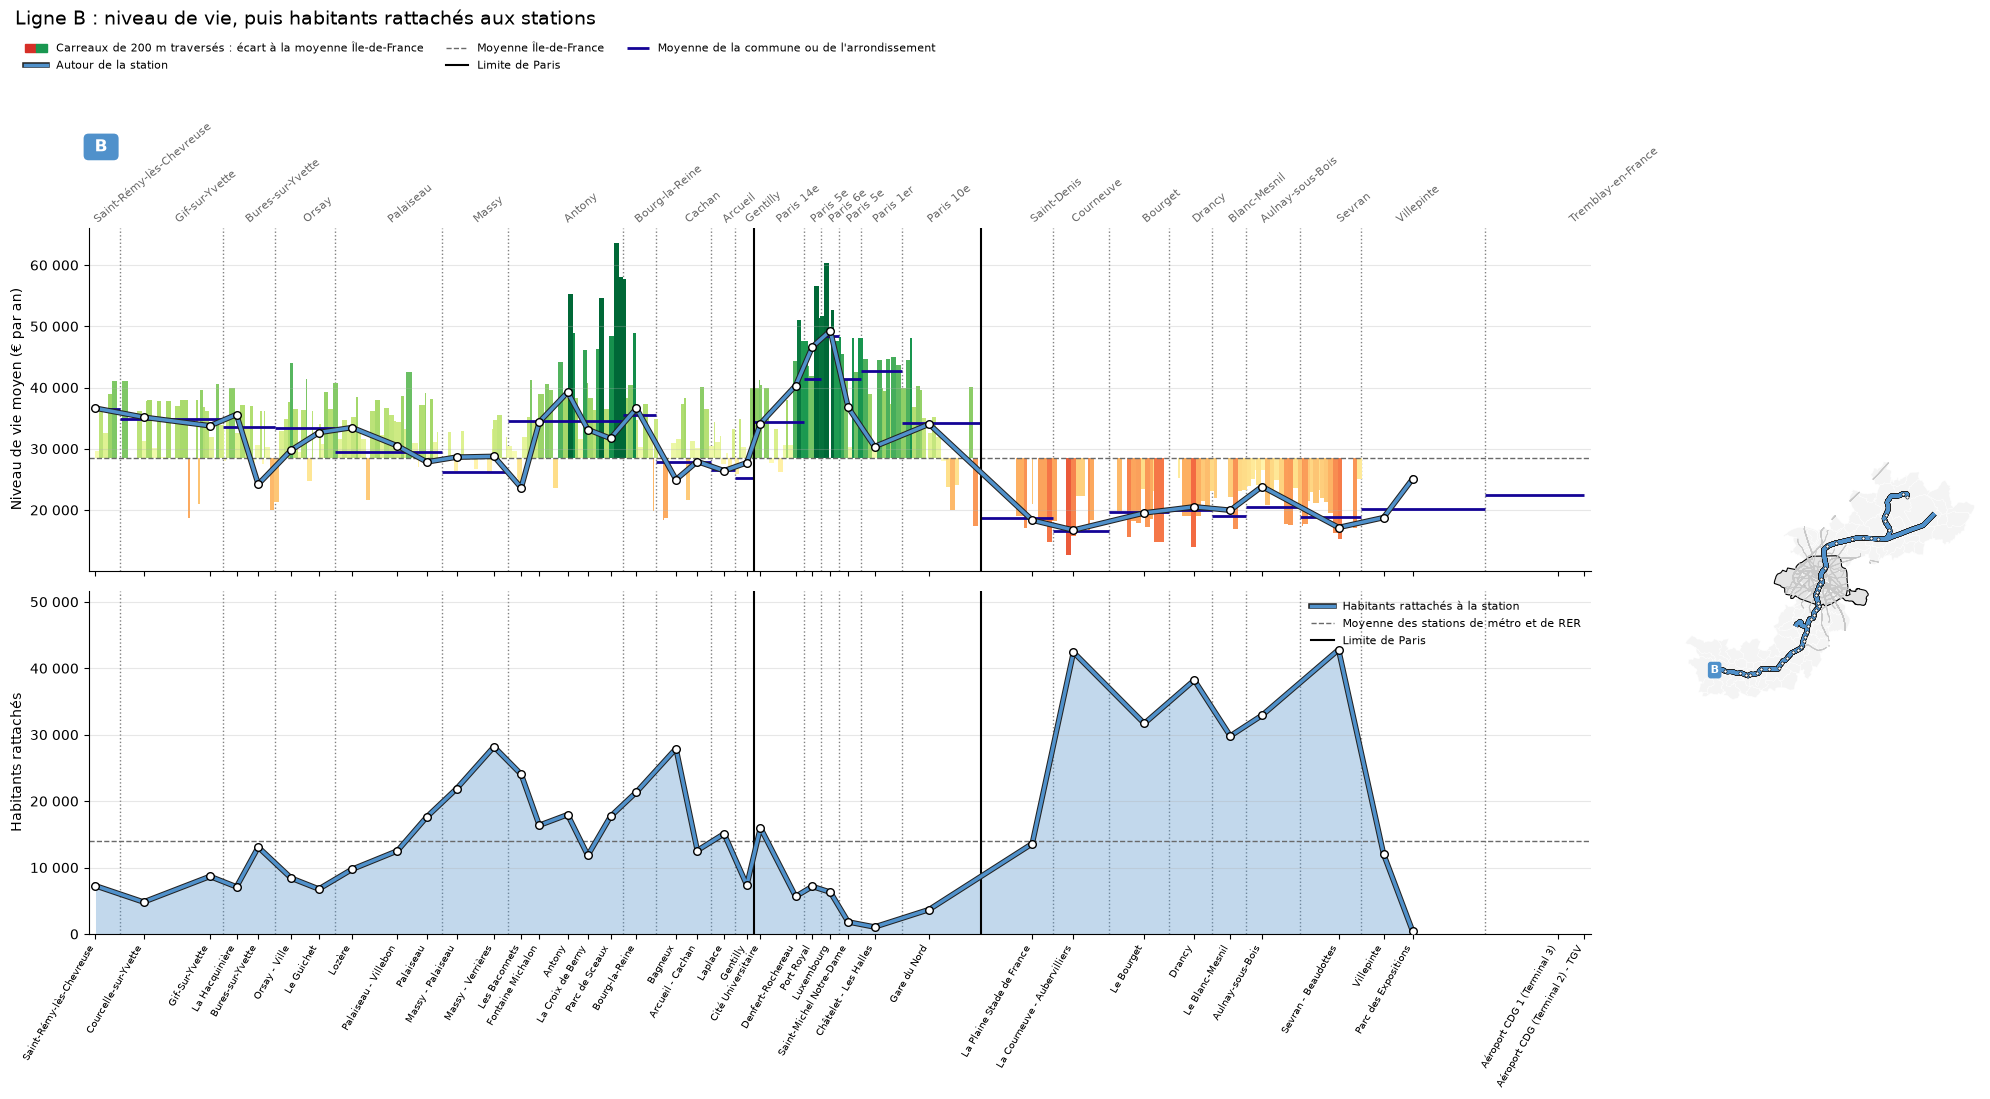

In [25]:
lignes_rer = preparer_lignes(["B", "A"])
# Même échelle pour les deux RER : le B est montré ici, le A en annexe
figures_rer = generer_montagnes_par_ligne(
    lignes_rer, df_nv, nv_moyen, nv_communes, gpd_idfm, gpd_communes
)
for nom, (ax_nv, _) in figures_rer.items():
    enregistrer_graphique(ax_nv, f"Ligne {nom} : niveau de vie et habitants")
    if nom != "B":
        plt.close(ax_nv.figure)
plt.show()

> **Lecture :** sur le RER B, entre Gare du Nord (10e arrondissement) et La Courneuve – Aubervilliers, le niveau de vie moyen autour de la station est divisé par deux : de 34 000 € à 16 700 € par an. Avec 42 400 habitants rattachés, La Courneuve – Aubervilliers en compte trois fois plus que la moyenne des stations de métro et de RER (14 000).
>
> *Champ : habitants des carreaux à moins de 1,5 km d'une station de métro ou de RER, rattachés à leur station la plus proche.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

#### Métro : lignes 13 et 1

Deux lignes opposées : la 13, la ligne de métro où les écarts de revenus sont les plus forts (voir II.3), et la 1, qui sort de Paris vers l'ouest. Les lignes 2, 9, 11 et 14 sont en annexe.

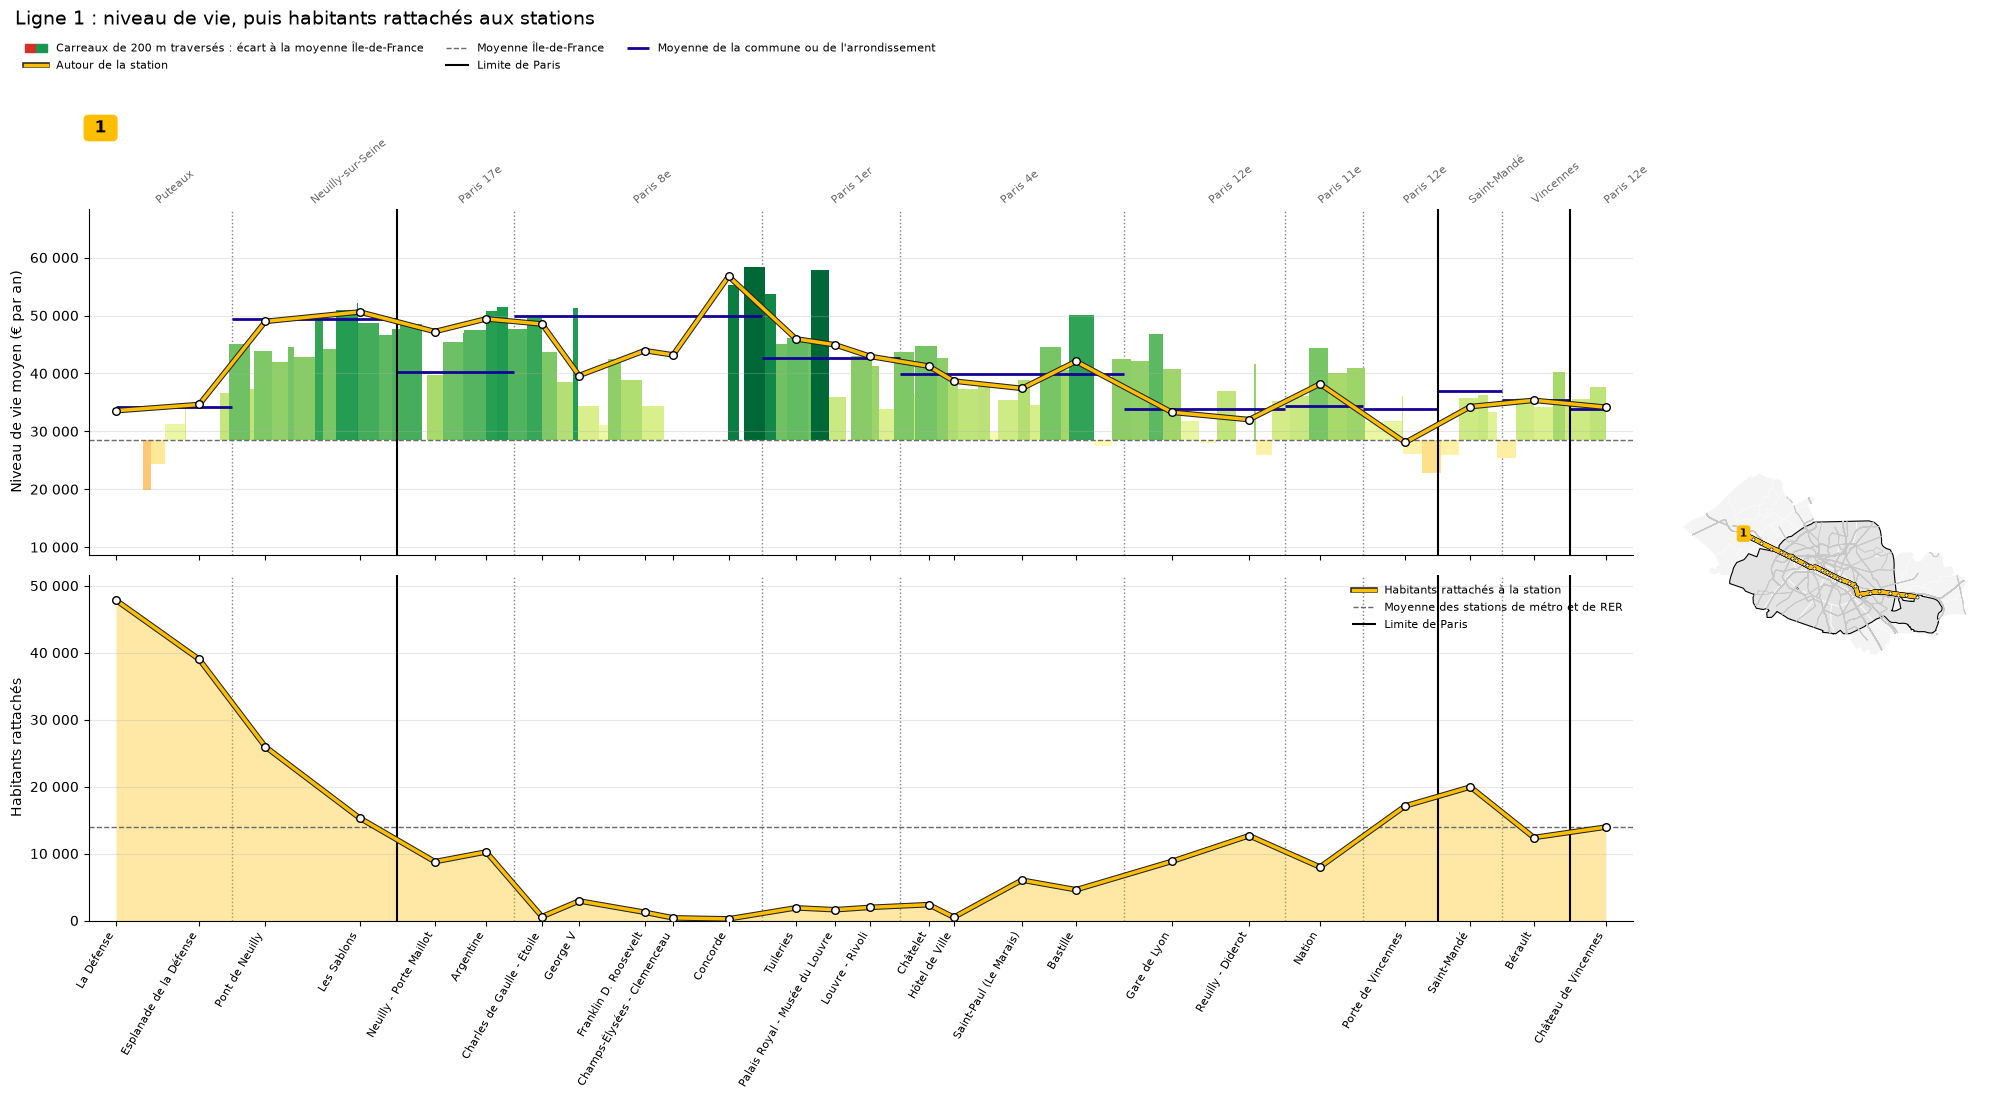

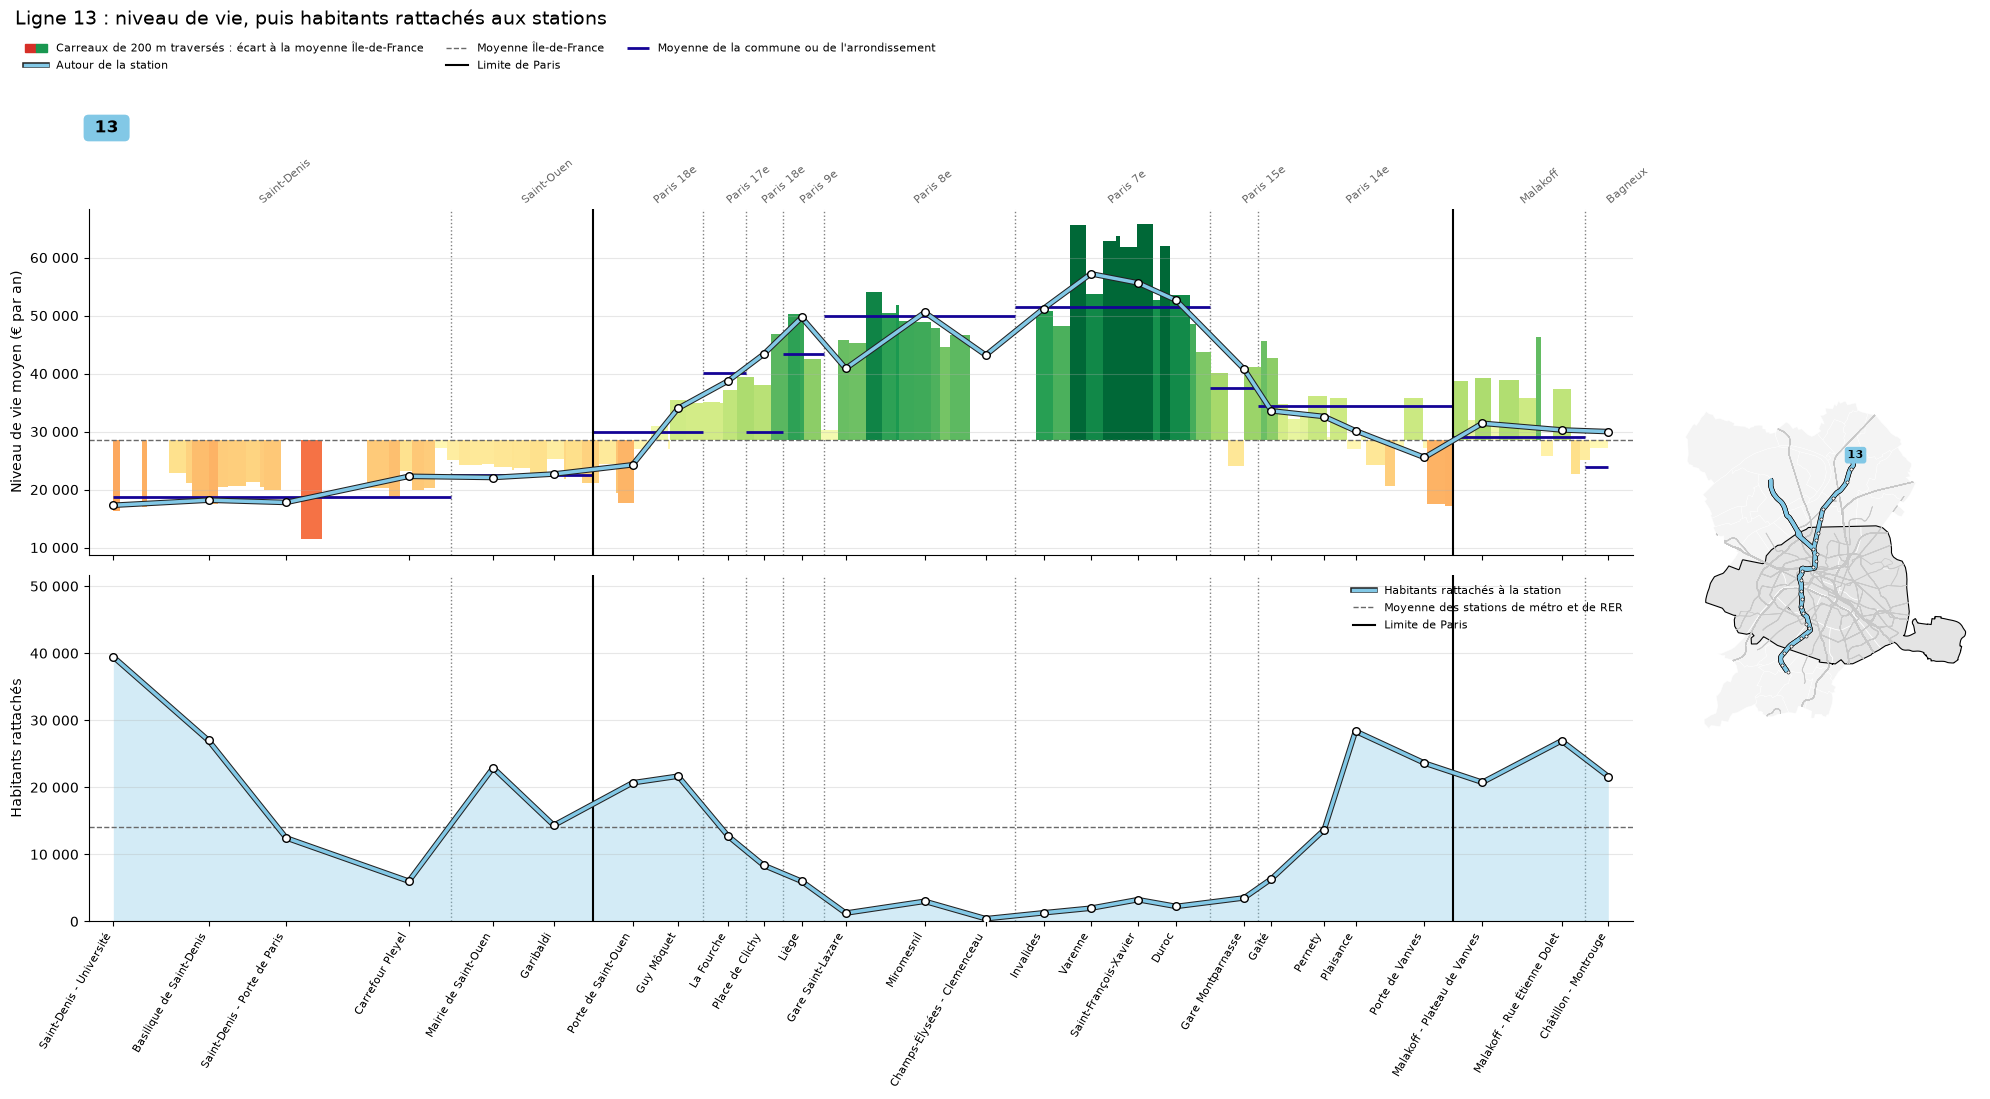

In [26]:
lignes_metro = preparer_lignes(["1", "2", "9", "11", "13", "14"])
# Même échelle pour les six lignes : la 1 et la 13 sont montrées ici, les autres en annexe
figures_metro = generer_montagnes_par_ligne(
    lignes_metro, df_nv, nv_moyen, nv_communes, gpd_idfm, gpd_communes
)
for nom, (ax_nv, _) in figures_metro.items():
    enregistrer_graphique(ax_nv, f"Ligne {nom} : niveau de vie et habitants")
    if nom not in ["1", "13"]:
        plt.close(ax_nv.figure)
plt.show()

> **Lecture :** sur la ligne 13, les 39 400 habitants rattachés à la station Saint-Denis – Université ont un niveau de vie moyen de 17 300 € par an, en dessous de la moyenne de l'Île-de-France (28 500 €). 12 km plus loin, autour de Varenne (7e arrondissement), il atteint 57 200 €, soit plus de trois fois plus, mais pour moins de 2 000 habitants.
>
> Sur la ligne 1, au contraire, sortir de Paris par l'ouest ne fait pas descendre la "montagne" : autour des Sablons (Neuilly-sur-Seine), le niveau de vie moyen est de 50 600 €, plus que dans toutes les stations parisiennes de la ligne sauf Concorde (qui n'a cependant que 300 habitants dans ses carreaux associés).
>
> *Champ : habitants des carreaux à moins de 1,5 km d'une station de métro ou de RER, rattachés à leur station la plus proche.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

### II.3 Hétérogénéité des lignes : effet Paris et banlieues riches

Les montagnes montrent de forts écarts de revenus le long de certaines lignes. Pour comparer toutes les lignes, nous posons trois questions :

1. **Quelles lignes relient les quartiers les plus différents ?**
2. **Est-ce seulement un effet de la limite de Paris ?** Le niveau de vie fait souvent une marche au périphérique.
3. **Les banlieues riches cassent-elles l'opposition « Paris riche, banlieue pauvre » ?**

**Méthode.** Les 16 lignes de métro et les 5 RER, limités à Paris et à la petite couronne, sont découpés en tronçons de 500 m, avec les habitants à moins de 400 m du tracé. 500 m soit environ une minute de métro (1,8 min par km en petite couronne d'après la partie I). Les indicateurs portent sur le log du niveau de vie, donc les écarts de niveau de vie se lisent en % :

- **volatilité** : écart-type des variations d'un tronçon au suivant, soit l'écart de niveau de vie typique pour une minute de trajet ;
- **dispersion** : écart-type du niveau de vie sur toute la ligne, pondéré par la population ;
- **effet Paris** : part de la variance expliquée par le seul fait d'être dans Paris ou en banlieue ;
- **banlieue riche** : part des habitants de banlieue de la ligne qui vivent dans une commune plus riche que Paris.

Le détail des choix est en annexe A.1.

In [27]:
gpd_zones, nv_paris = classer_carreaux_zones(gpd_centres, gpd_communes)
df_profils_zones = calculer_profils_zones(
    gpd_idfm, gpd_zones, distance_max=400, longueur_troncon=500
)
df_heterogeneite = mesurer_heterogeneite_lignes(df_profils_zones)
print(f"Niveau de vie moyen à Paris : {nv_paris:,.0f} € par an".replace(",", " "))

# Tableau trié par dispersion, en % et en euros ; « — » : ligne entièrement dans Paris
pourcent = lambda v: "—" if v != v else f"{v:.0%}"
euros = lambda v: "—" if v != v else f"{v:,.0f} €".replace(",", " ")
df_heterogeneite.drop(columns=["couleur", "mode"]).transform(
    {
        "troncons": str, "volatilite": pourcent, "dispersion": pourcent,
        "effet_paris": pourcent, "nv_paris": euros, "nv_banlieue": euros,
        "part_banlieue_riche": pourcent,
    }
).rename(columns={
    "troncons": "Tronçons", "volatilite": "Volatilité", "dispersion": "Dispersion",
    "effet_paris": "Effet Paris", "nv_paris": "Niveau de vie Paris",
    "nv_banlieue": "Niveau de vie banlieue", "part_banlieue_riche": "Banlieue riche",
}).rename_axis("Ligne")

Niveau de vie moyen à Paris : 35 763 € par an


,Tronçons,Volatilité,Dispersion,Effet Paris,Niveau de vie Paris,Niveau de vie banlieue,Banlieue riche
Ligne,,,,,,,
C,69,15%,35%,60%,41 478 €,22 258 €,0%
B,75,15%,34%,40%,37 243 €,24 918 €,2%
E,69,14%,32%,8%,36 518 €,30 350 €,17%
13,36,15%,31%,43%,37 133 €,23 657 €,0%
7,43,11%,30%,47%,33 896 €,21 316 €,0%
D,58,14%,29%,44%,34 815 €,23 780 €,0%
12,35,13%,27%,18%,38 006 €,28 364 €,45%
14,50,14%,26%,47%,36 427 €,24 362 €,0%
A,66,16%,26%,20%,39 499 €,32 076 €,21%


> **Lecture :** le long de la ligne 13, le niveau de vie s'écarte de sa moyenne d'environ 31 % en général (dispersion) et varie d'environ 15 % d'un tronçon de 500 m au suivant (volatilité). 43 % de ces écarts de revenus s'expliquent par le seul fait d'être dans Paris ou en banlieue (effet Paris). Aucune de ses banlieux est plus riche que Paris.
>
> *Champ : habitants à moins de 400 m du tracé, à Paris et en petite couronne ; tronçons d'au moins 100 habitants.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

#### Dans Paris et en banlieue, ligne par ligne

Point plein : niveau de vie moyen le long de la ligne dans Paris ; point creux : en banlieue. Plus le trait est long, plus la sortie de Paris change le niveau de vie. À droite, l'effet Paris et la part des habitants de banlieue de la ligne qui vivent dans une commune plus riche que Paris.

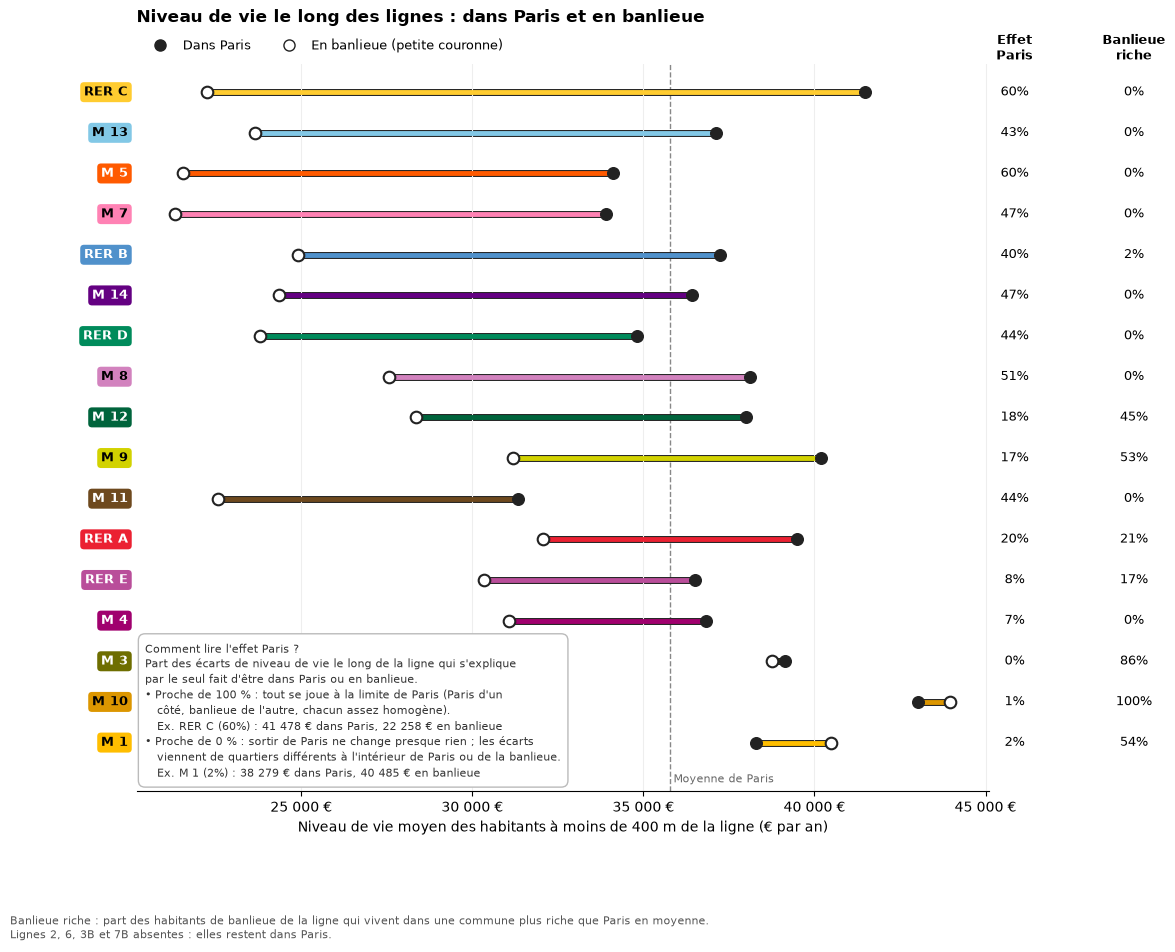

In [28]:
ax = generer_halteres_paris_banlieue(df_heterogeneite, nv_paris)
enregistrer_graphique(ax, "Hétérogénéité : Paris et banlieue par ligne")
plt.show()

> **Lecture :** le long de la ligne 13, les habitants des tronçons situés dans Paris ont un niveau de vie moyen de 37 100 € par an, contre 23 700 € pour ceux des tronçons de banlieue, soit 36 % de moins. Sur la ligne 1, c'est l'inverse : la banlieue (40 500 €) est plus riche que Paris (38 300 €), et 54 % de ses habitants de banlieue vivent dans une commune plus riche que Paris, comme Neuilly-sur-Seine.
>
> *Champ : habitants à moins de 400 m du tracé, à Paris et en petite couronne ; lignes 2, 6, 3B et 7B exclues (entièrement dans Paris).* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

**Commentaire**

- **Les lignes où les écarts de revenus sont les plus forts** sont les RER C, B et E, puis la ligne 13, la 7 et le RER D (dispersion de 29 à 35 %). Les plus homogènes en revenus sont la 10 et la 1 (11 et 17 %).
- **La limite de Paris explique une grande partie des écarts de revenus, mais pas tout** : de 40 à 60 % de la variance sur les lignes C, 5, 8, 7, 14, 11, D, 13 et B. Sur le RER E (8 %), la 9 (17 %), la 12 (18 %) et le RER A (20 %), les écarts de revenus viennent surtout de l'intérieur de Paris ou de la banlieue.
- **Vers l'ouest, la banlieue n'est pas plus pauvre que Paris.** Sur les lignes 1, 3 et 10, l'effet Paris est presque nul (0 à 2 %), et 54 à 100 % de leurs habitants de banlieue vivent dans une commune plus riche que Paris, comme Neuilly-sur-Seine (carte en annexe A.3). À l'inverse, aucun habitant de banlieue des lignes 4, 5, 7, 8, 11, 13, 14 et des RER C et D ne vit dans une commune plus riche que Paris.

### Conclusion de la partie II

**Être proches en métro ne veut pas dire être proches en revenus.** Sur la ligne 13 comme sur le RER B, quelques stations suffisent pour que le niveau de vie soit divisé par deux, voire par trois. Ces écarts de revenus ne suivent pas un simple gradient du centre vers la périphérie : ils opposent l'ouest et le sud-ouest, aisés des deux côtés du périphérique, au nord et à l'est, plus modestes. La limite de Paris en explique souvent près de la moitié, mais elle s'efface vers l'ouest, où la banlieue est aussi riche que Paris, voire plus.

C'est pourquoi le temps de trajet vers le pôle le plus proche ne rend compte que d'une petite part des inégalités (partie I) : la direction dans laquelle on s'éloigne du centre compte autant que la distance parcourue.


Pour aller plus loin sur l'explication de cette distribution : 
Stephan Heblich, Alex Trew et Yanos Zylberberg, « East-Side Story: Historical Pollution and Persistent Neighborhood Sorting » (publié dans le Journal of Political Economy, 2021 ; [version de travail accessible via le Centre for Economic Performance de la LSE](https://cep.lse.ac.uk/pubs/download/sercdp0208.pdf)

### Limites

- **Centre de Paris** : les stations sont si proches que chacune ne récupère que quelques carreaux (248 habitants pour Concorde, contre 48 000 pour La Défense). Les valeurs par station y sont fragiles ; les barres des carreaux le sont moins.
- **Lignes à branches** (13, RER A et B) : la montagne ne suit que la branche la plus longue.
- **Une seule station par habitant** : chacun est rattaché à sa station la plus proche, métro compris. Les gares du RER dans Paris (Auber, Châtelet - Les Halles…) ont donc très peu d'habitants rattachés.
- **Carreaux sans habitants** (Seine, parcs, aéroport CDG) : ils n'apparaissent pas ; ce sont les trous des montagnes.

# Conclusion

La proximité en métro n'est pas gage de proximité en revenus. Le réseau, organisé en étoile autour du centre, suit un gradient centre-périphérie et reflète par la même occasion les inégalités socio-économiques du territoire.

Au-delà de la centralité bien établie des niveaux de vie en Île-de-France, à l'instar de celle du réseau de transports en commun, l'étude des niveaux de vie le long du réseau IDFM révèle deux grands types de fractures socio-économiques. 

La première est celle de l'accessibilité des grands pôles économiques par les transports en commun. Si les ménagse les plus aisés ont plus facilement accès au centre par le métro que les autres, cela s'avère moins évident pour la banlieue plus lointaine, où les transports en commun paraissent être davantage l'apanage des ménages plus modestes. 

La seconde est la fracture du périphérique, qui sépare souvent sur la même ligne des quartiers à quelques minutes les uns des autres. Cela étant dit, cette fracture n'est pas uniforme ; si elle est très affirmée sur l'axe nord-sud, elle s'efface à l'ouest.

Des territoires proches par les transports en communs peuvent ainsi être très éloignés par leur niveau de vie moyen.

## Annexes

### A.1 Méthode de mesure de l'hétérogénéité

- **Lignes** : les 16 métros et les 5 RER, limités à Paris et à la petite couronne (Hauts-de-Seine, Seine-Saint-Denis, Val-de-Marne). Sans cette limite, les RER (50 à 80 km) dépendraient surtout de la grande couronne et ne seraient pas comparables aux métros.
- **Tronçons de 500 m** le long du tracé (le plus long de chaque ligne), avec les habitants à moins de 400 m. Toutes les lignes sont mesurées avec la même règle, quel que soit l'espacement des stations : on mesure le territoire *traversé*, pas seulement celui desservi par chaque station. Les tronçons de moins de 100 habitants sont écartés.
- **Zone** : un tronçon est « Paris » si la majorité de ses habitants vit dans Paris, « banlieue » sinon.
- **Volatilité** : écart-type des variations du log du niveau de vie d'un tronçon au suivant, comme la volatilité d'un cours de bourse, avec « par 500 m » au lieu de « par jour ».
- **Effet Paris** : variance entre les deux zones divisée par la variance totale. 60 % veut dire que 60 % des écarts de niveau de vie le long de la ligne s'expliquent par la limite de Paris ; le reste vient des écarts à l'intérieur de Paris et à l'intérieur de la banlieue.
- **Banlieue riche** : commune de petite couronne dont le niveau de vie moyen dépasse celui de Paris.

### A.2 Autres montagnes : RER A et lignes de métro 2, 9, 11 et 14

Mêmes figures et mêmes échelles qu'en II.2. Le RER A est l'autre grande traversée de la région, d'ouest en est.

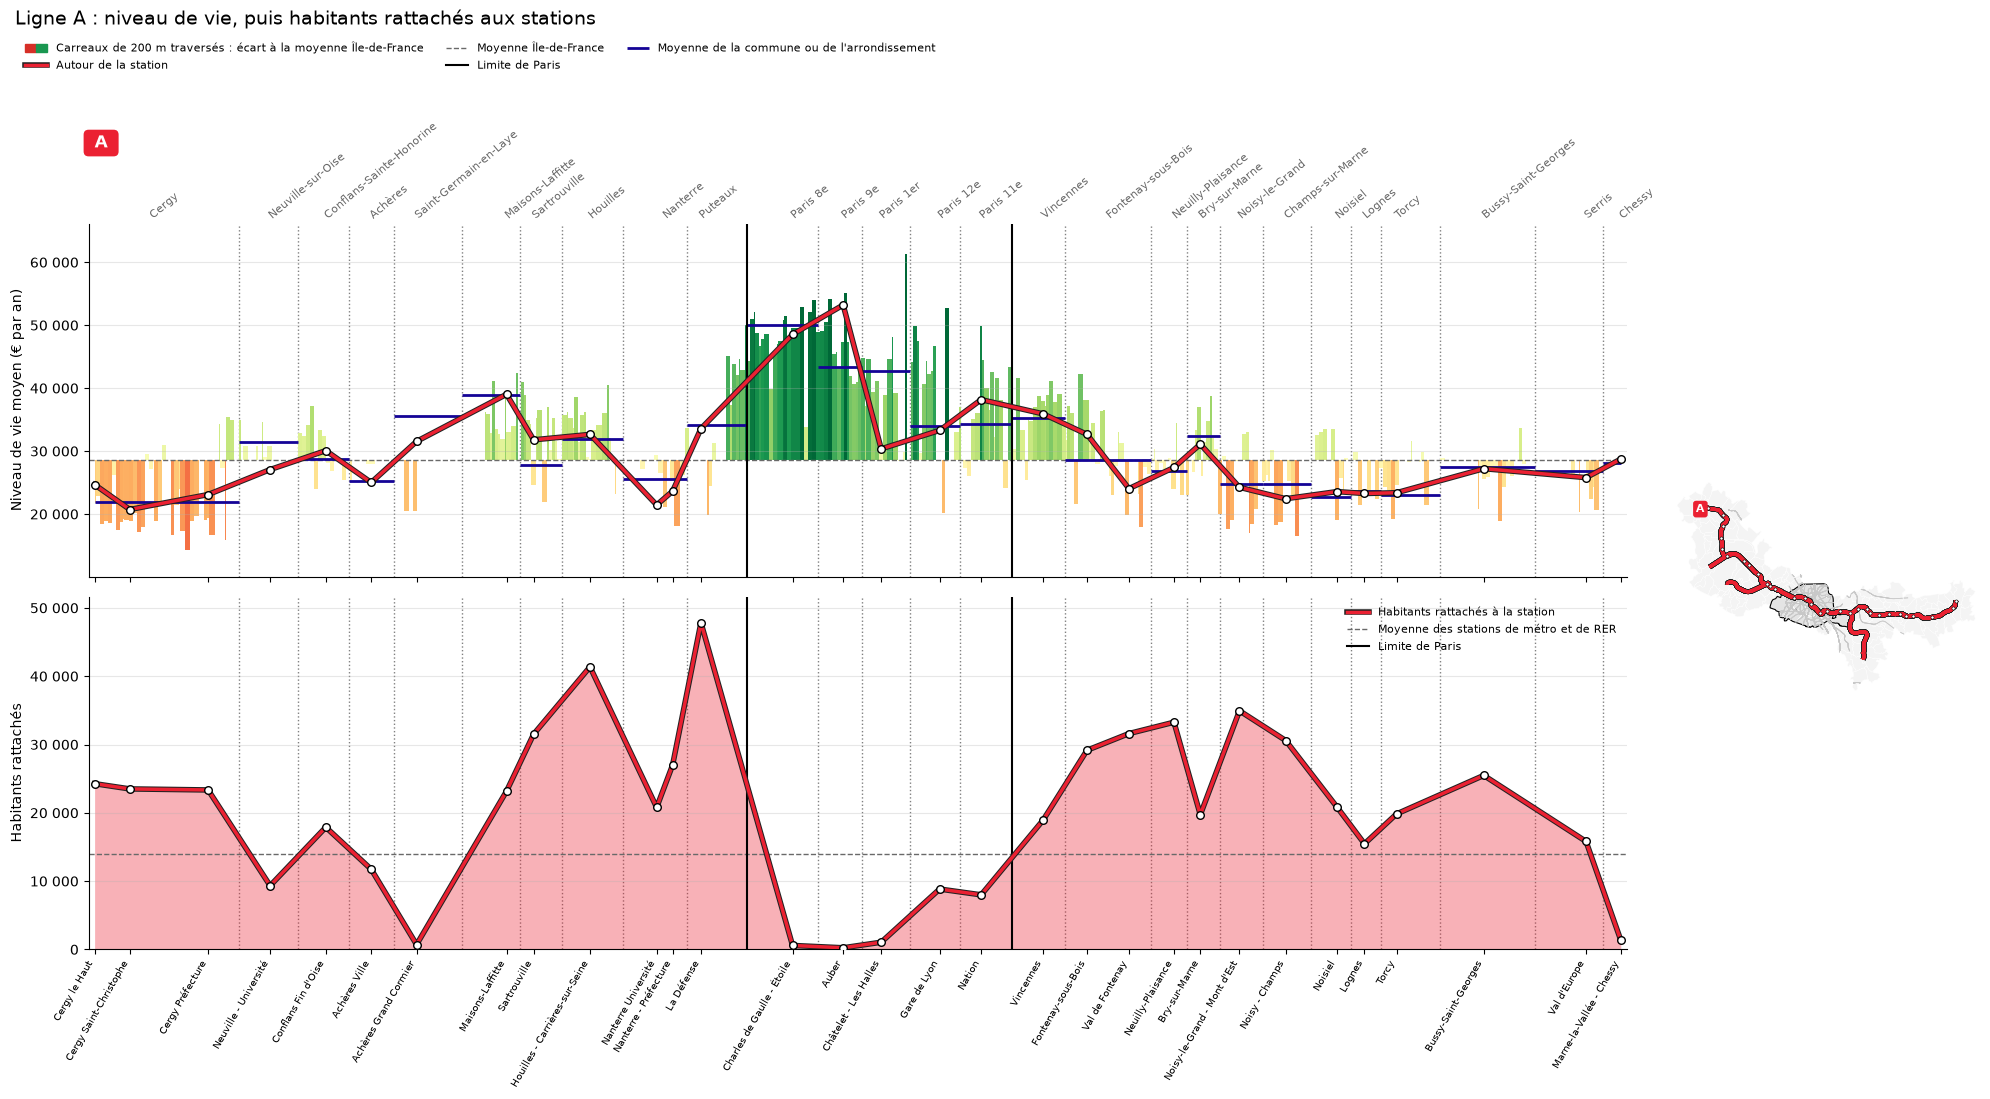

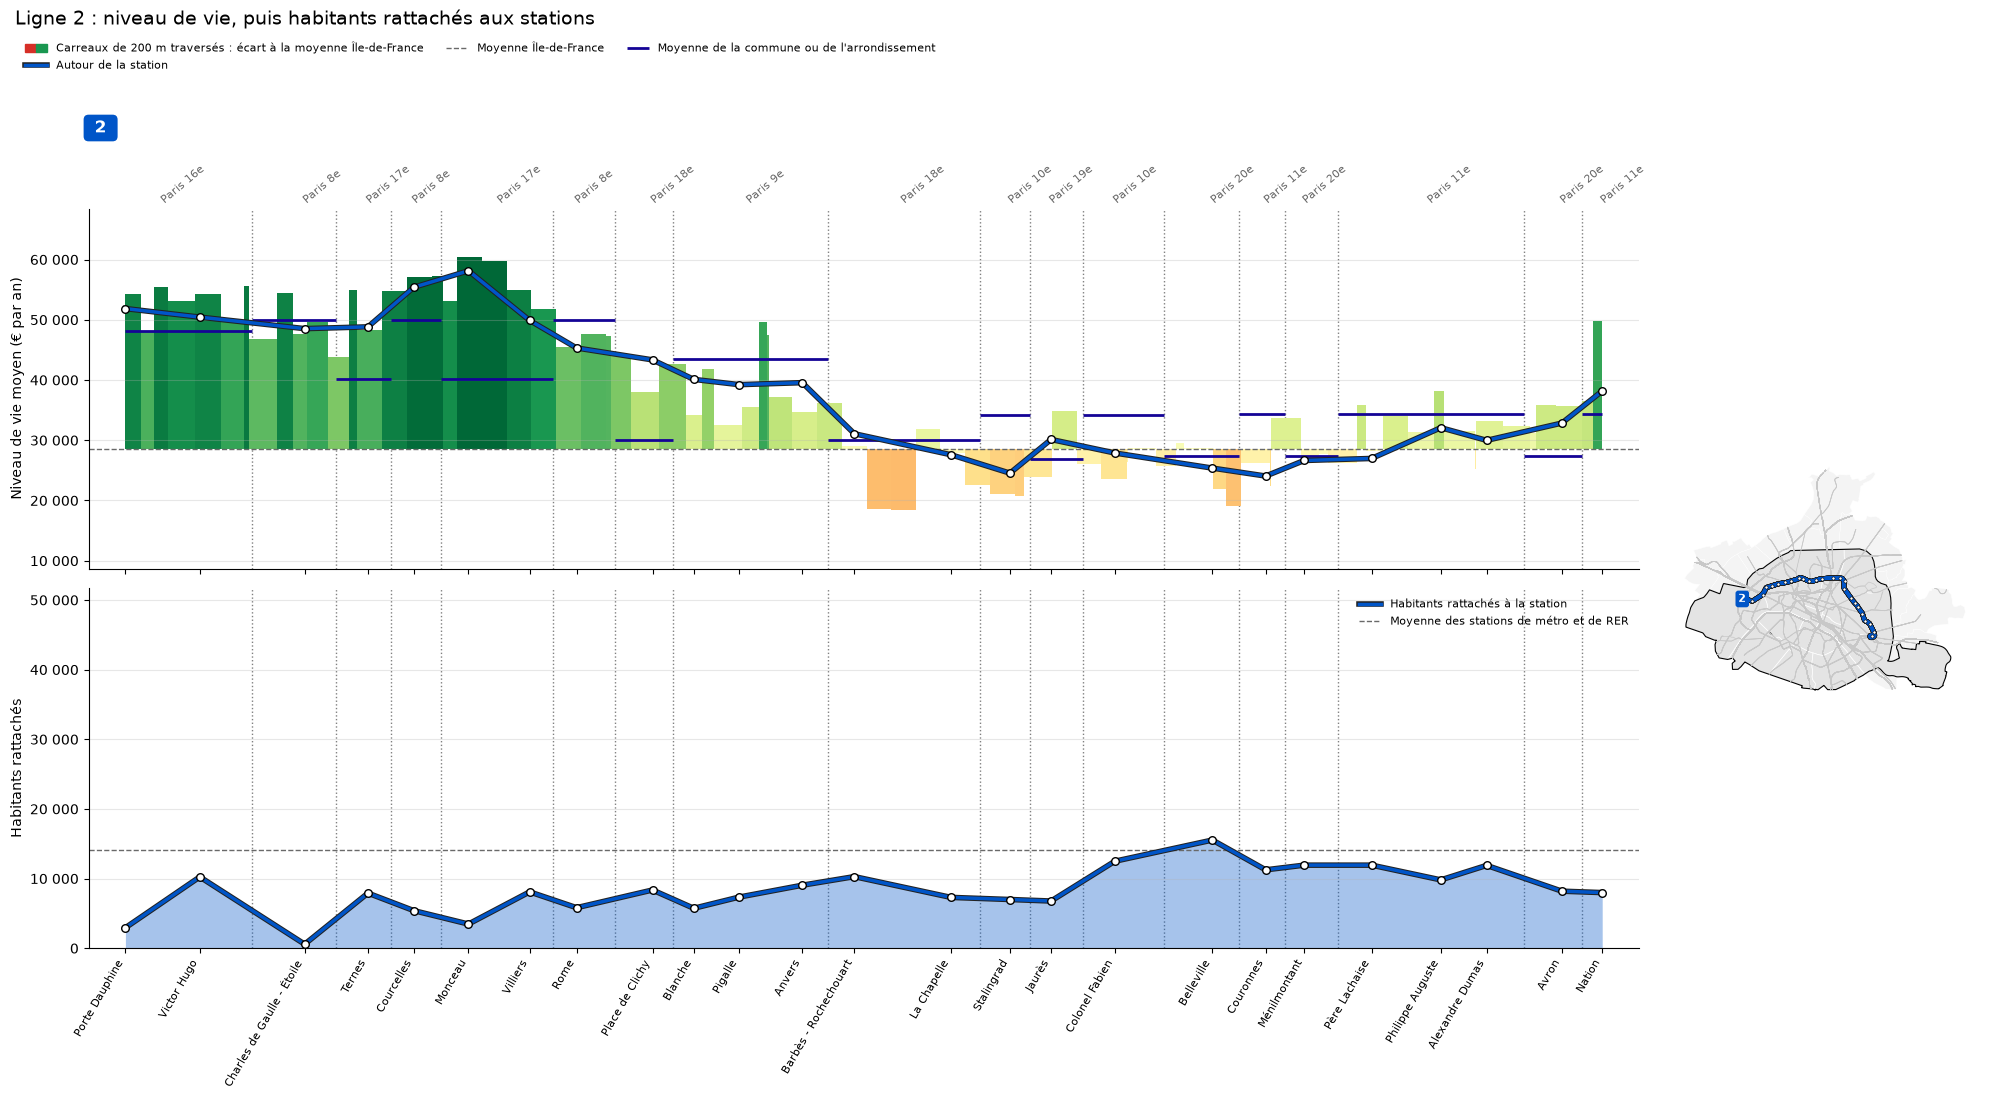

In [ ]:
from IPython.display import display

# Figures déjà calculées en II.2 (mêmes échelles que le RER B et les lignes 1 et 13)
display(figures_rer["A"][0].figure)
for nom in ["2", "9", "11", "14"]:
    display(figures_metro[nom][0].figure)

### A.3 Les banlieues plus riches que Paris

En vert, les communes de petite couronne dont le niveau de vie moyen dépasse celui de Paris (plus le vert est foncé, plus elles sont riches) ; les lignes de métro et de RER par-dessus.

In [ ]:
ax = generer_carte_communes_riches(gpd_communes, gpd_zones, nv_paris, gpd_idfm)
enregistrer_graphique(ax, "Communes plus riches que Paris")
plt.show()

> **Lecture :** Neuilly-sur-Seine, la commune la plus riche de la petite couronne, a un niveau de vie moyen de 49 300 € par an, 38 % de plus que Paris (35 800 €). Seize communes dépassent Paris : quinze dans les Hauts-de-Seine, surtout à l'ouest, et Saint-Mandé dans le Val-de-Marne ; aucune en Seine-Saint-Denis.
>
> *Champ : habitants de Paris et de la petite couronne.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

### A.4 Le relief du niveau de vie à Paris

Chaque point de la surface est le niveau de vie moyen des habitants dans un carré de 1 km de côté centré sur lui (moyenne pondérée par la population, sur la grille de 200 m de Filosofi), lissant le relief sans effacer les quartiers.

- **Couleurs** : les mêmes que les montagnes, rouge sous la moyenne de l'Île-de-France, vert au-dessus.
- **Trous** : pas d'habitants (bois de Boulogne et de Vincennes, grands parcs).

In [ ]:
# Figure interactive : clic gauche + glisser pour tourner, clic droit pour zoomer
%matplotlib widget
from IPython.display import display

gpd_paris = gpd_communes[gpd_communes["nom"].str.startswith("Paris")].to_crs(3035)
grille = construire_grille_nv(df_filosofi, gpd_paris.union_all(), rayon=2)

# Lignes mises en valeur au départ : celles des montagnes ; les autres sont en gris
selection = list(lignes_metro)
with plt.ioff():  # on affiche nous-mêmes la figure, sous les boutons
    ax, traits = generer_relief_3d(grille, nv_moyen, gpd_idfm, gpd_paris, selection)
enregistrer_graphique(ax, "Relief 3D du niveau de vie à Paris")
display(ajouter_selecteur_lignes(ax, traits, selection), ax.figure.canvas)

> **Lecture :** le point le plus haut du relief, dans le 16e arrondissement, correspond à un niveau de vie moyen de 59 100 € par an (moyenne sur un carré de 1 km de côté) ; le point le plus bas, dans le 18e, est à 16 400 €, soit 3,6 fois moins.
>
> *Champ : habitants de Paris ; points avec au moins 100 habitants dans le carré de 1 km.* *Sources : Insee, Filosofi 2021 (carreaux de 200 m) ; Île-de-France Mobilités (GTFS).*

Les sommets, là où le niveau de vie est le plus élevé (ouest de Paris : 7e, 8e, 16e, 17e), sont aussi très bien desservis : les lignes 2, 9 et 13 les traversent avant de redescendre vers des quartiers plus modestes. Le principal nœud du réseau, Châtelet, se trouve lui en contrebas de ces sommets.

Attention : ce rendu est lissé sur 1 km et efface les contrastes de revenus très locaux (une cité HLM à côté d'une rue aisée).